# 04 — ERF trên 100 ảnh: loader chung, shared crop và kiểm định ghép cặp

Notebook này phân tích độ nhạy của đặc trưng gần tâm qua 4 giai đoạn ResNet-50 và ViT-B/16.
**Toàn bộ code ERF và thống kê đã nằm trong notebook.** Không cần `erf_statistics.py`.
Các helper ERF cũng có bản phát triển ở `experiments/erf/erf_experiment.py`.

Theo protocol mới, model và ảnh được nạp qua **`src/models.py`, `src/data.py`** của nhóm.
Vì vậy Colab cần thư mục project đã cập nhật các module chung và manifest, cùng dữ liệu gốc.
`src/evaluation.py` không dùng để lấy gradient ERF; ERF có metric riêng, không tính accuracy drop.

**Phạm vi:** 100 ảnh lấy từ manifest 10.000 ảnh, seed 42. Đây là subset thử nghiệm,
không phải toàn bộ tập 1.000 lớp hay kết quả đầy đủ của analysis set.
Target, vị trí, scalar và các giới hạn được ghi ở Bước 3–5 để nhóm duyệt phương pháp.

**Tiếp tục trên Colab:** chạy Bước 0–5 và ô định nghĩa `run_experiment` ở Bước 6,
rồi Bước 8a–8c để nạp lại official cũ và chạy shared crop. Nếu chưa có official hoàn chỉnh,
chạy thêm Bước 7. Không cần chạy smoke test lại nếu đã kiểm tra trước đó.
Kết quả `official` cũ được giữ trong phụ lục lịch sử; các ô đã sửa chưa có output mới.

## Bước 0 — Kiểm tra nơi chạy

Trên [Google Colab](https://colab.research.google.com/), chọn **File → Upload notebook**,
mở file này, rồi vào **Runtime → Change runtime type → chọn GPU** nếu được cấp.
Chạy ô dưới. `CUDA: True` nghĩa là PyTorch nhìn thấy GPU.
`False` vẫn chạy thử được bằng CPU, nhưng hãy kiểm tra lại runtime trước khi chạy nhiều ảnh.

Colab thường có sẵn torch/torchvision. Nếu thiếu thư viện phụ, ô này cài vào đúng kernel.
Khi dùng máy cá nhân, cài bộ torch/torchvision phù hợp theo
[hướng dẫn PyTorch](https://pytorch.org/get-started/locally/) trước.

In [1]:
import importlib.util
import subprocess
import sys

missing = [package for package in ['numpy', 'pandas', 'matplotlib', 'PIL', 'pyarrow', 'tqdm', 'scipy']
           if importlib.util.find_spec(package) is None]
if missing:
    packages = ['pillow' if name == 'PIL' else name for name in missing]
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *packages])

import torch
import torchvision

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__, '| torchvision:', torchvision.__version__)
print('CUDA:', torch.cuda.is_available())
print('Thiết bị:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU')

Python: 3.13.16
PyTorch: 2.11.0+cu130 | torchvision: 0.26.0+cu130
CUDA: True
Thiết bị: Tesla T4


In [2]:
import hashlib
import inspect
import json
from pathlib import Path
import random
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from tqdm.auto import tqdm

LAYERS = {
    "resnet50": ["layer1", "layer2", "layer3", "layer4"],
    "vit_b_16": ["block3", "block6", "block9", "block12"],
}

## Bước 1 — Dùng đúng project, module và dữ liệu của nhóm

Thư mục project cần các file mới từ `main`: `src/models.py`, `src/data.py`, `src/evaluation.py`,
`src/evaluate_baseline.py`, `README.md`, `docs/experiment_protocol.md` và manifest/config hiện có.
Notebook không tự tải code Python từ một URL và không thay loader chung bằng bản viết riêng.

Trên Colab, đặt project trong `MyDrive/cnn-vit-interpretability/`, mount Drive rồi sửa
`PROJECT_ROOT` nếu cần. Cần đủ 14 shard `data/imagenet/data/validation-*.parquet`.
Có thể copy shard vào runtime để giảm I/O và sửa `DATA_DIR`; giữ kết quả trên Drive.

`ALLOW_DOWNLOAD = False` yêu cầu weights đã có trong cache. Đổi thành `True` nếu cần
cho phép `src.models.load_model` tải đúng checkpoint baseline từ máy chủ PyTorch.
Không dùng `DEFAULT`, checkpoint timm hoặc tự thay preprocessing baseline.

In [3]:
IS_COLAB = importlib.util.find_spec('google.colab') is not None if importlib.util.find_spec('google') else False
if IS_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from google.colab import files
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile

root = Path('/content/drive/MyDrive/cnn-vit-interpretability')
assert root.is_dir(), 'Kiểm tra mount Drive và đường dẫn project.'

uploaded = files.upload()
with ZipFile(BytesIO(next(iter(uploaded.values())))) as archive:
    archive.extractall(root)

print('Đã cập nhật module và protocol vào Drive.')

Saving shared_modules_main_fd4a8ae.zip to shared_modules_main_fd4a8ae.zip
Đã cập nhật module và protocol vào Drive.


In [5]:
if IS_COLAB:
    PROJECT_ROOT = Path('/content/drive/MyDrive/cnn-vit-interpretability')
else:
    PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                         if (p / 'configs/analysis_set.json').is_file()), None)
    if PROJECT_ROOT is None:
        raise FileNotFoundError('Mở notebook từ repo hoặc sửa PROJECT_ROOT bằng đường dẫn đầy đủ.')

DATA_DIR = PROJECT_ROOT / 'data/imagenet/data'
# Cập nhật các module chung trong thư mục project trên Drive trước khi chạy.
required_shared = ['src/models.py', 'src/data.py', 'src/evaluation.py', 'docs/experiment_protocol.md']
missing_shared = [name for name in required_shared if not (PROJECT_ROOT / name).is_file()]
if missing_shared:
    raise FileNotFoundError(f'Project chưa có cập nhật main: {missing_shared}. Đồng bộ repo rồi chạy lại.')
sys.path.insert(0, str(PROJECT_ROOT))
OUTPUT_BASE = PROJECT_ROOT / 'results/metrics/experiments/erf'
FIGURE_BASE = PROJECT_ROOT / 'results/figures/experiments/erf'
LEGACY_OUTPUT_BASE = PROJECT_ROOT / 'results/metrics/erf'
# False: dùng weights cache. True: cho phép src.models tải checkpoint chính thức nếu thiếu.
ALLOW_DOWNLOAD = False
print('Project:', PROJECT_ROOT)
print('Số shard validation:', len(list(DATA_DIR.glob('validation-*.parquet'))), '/ 14')
print('Config:', (PROJECT_ROOT / 'configs/analysis_set.json').is_file())
print('Manifest:', (PROJECT_ROOT / 'data/manifests/analysis_10000_seed42.csv').is_file())

Project: /content/drive/MyDrive/cnn-vit-interpretability
Số shard validation: 14 / 14
Config: True
Manifest: True


## Bước 2 — Chọn đúng 100 ảnh, dùng chung cho hai model và hai chế độ crop

Kiểm tra SHA-256 của manifest gốc rồi lấy ngẫu nhiên **100 ảnh bằng seed 42**.
Không lấy 100 dòng đầu vì manifest sắp theo ID, có thể tạo thiên lệch.
Đây là lấy mẫu đều theo ảnh, không cân bằng đủ 1.000 lớp. Cùng `records` được
sử dụng cho `official`, `shared_vit_crop` và các phép kiểm định.

Giữ `NUM_IMAGES = 100`, `SEED = 42` để khớp run `official` đã lưu.
Bước 8a sẽ từ chối nếu CSV cũ không khớp chính xác ID, nhãn và dataset index.
Để xác minh toàn bộ shard, dùng `src/create_analysis_manifest.py --check`.

In [6]:
# These imports run after PROJECT_ROOT is added to sys.path in the notebook.
from src.models import load_model
from src.data import load_analysis_manifest, iter_analysis_images


def select_records(project_root, num_images=100, seed=42):
    """Validate the shared manifest, then choose a reproducible pilot cohort."""
    root = Path(project_root)
    config = json.loads((root / "configs/analysis_set.json").read_text("utf-8"))
    manifest = root / config["manifest"]
    normalized = manifest.read_bytes().replace(b"\r\n", b"\n")
    if hashlib.sha256(normalized).hexdigest() != config["manifest_sha256"]:
        raise ValueError("Analysis manifest checksum differs from the shared config.")
    records = load_analysis_manifest(manifest)  # Validate all 10,000 IDs; no first-N limit.
    if not isinstance(num_images, int) or isinstance(num_images, bool) or not 1 <= num_images <= len(records):
        raise ValueError("num_images must be an integer between 1 and 10,000.")
    chosen = random.Random(seed).sample(sorted(records, key=lambda row: row["image_id"]), num_images)
    return sorted(chosen, key=lambda row: row["dataset_index"])


def load_images(data_dir, records):
    """Adapt the shared RGB iterator to ERF; consume fully to validate missing IDs."""
    records = list(records)
    wanted = {row["image_id"]: row for row in records}
    if not wanted or len(wanted) != len(records):
        raise ValueError("Provide nonempty unique image IDs.")
    for image, label, image_id in iter_analysis_images(records, data_dir=data_dir):
        record = wanted[image_id]
        if label != record["label"]:
            raise ValueError(f"Label mismatch: {image_id}")
        yield record, image


def erf_output_paths(project_root, run_id):
    """Return protocol-compliant metrics, figures, and ignored intermediates."""
    if not run_id or Path(run_id).name != run_id or any(c in run_id for c in '/\\') or run_id in {'.', '..'}:
        raise ValueError("run_id must be a single nonempty directory name.")
    root = Path(project_root)
    run_root = root / "results/metrics/experiments/erf" / run_id
    return (run_root / "final",
            root / "results/figures/experiments/erf" / run_id / "final",
            run_root / "intermediate")


def erf_code_provenance(project_root):
    root = Path(project_root)
    def git_output(*arguments):
        try:
            return subprocess.check_output(["git", "-C", str(root), *arguments],
                                           stderr=subprocess.DEVNULL, text=True).strip()
        except (OSError, subprocess.CalledProcessError):
            return None
    revision = git_output("rev-parse", "HEAD")
    status = git_output("status", "--porcelain", "--untracked-files=normal")
    # Drive may contain a file copy without .git; record unknown explicitly.
    files = ["experiments/erf/erf_experiment.py", "notebooks/04_erf_100.ipynb",
             "src/models.py", "src/data.py", "src/evaluation.py"]
    return {"git_revision": revision, "git_dirty": None if status is None else bool(status),
            "file_sha256": {name: hashlib.sha256((root / name).read_bytes()).hexdigest()
                            for name in files if (root / name).is_file()}}

In [7]:
SEED = 42
NUM_IMAGES = 100
PREPROCESSING = 'official'
records = select_records(PROJECT_ROOT, NUM_IMAGES, SEED)
display(pd.DataFrame(records))
print('Số lớp trong tập nhỏ:', len({row['label'] for row in records}))

,dataset_index,image_id,label
0,415,ILSVRC2012_val_00030161_n03584254.JPEG,605
1,433,ILSVRC2012_val_00049873_n03272010.JPEG,546
2,690,ILSVRC2012_val_00027955_n02437312.JPEG,354
3,738,ILSVRC2012_val_00028447_n03777568.JPEG,661
4,883,ILSVRC2012_val_00003875_n01950731.JPEG,115
...,...,...,...
95,47071,ILSVRC2012_val_00029577_n11879895.JPEG,984
96,47104,ILSVRC2012_val_00019301_n03995372.JPEG,740
97,48523,ILSVRC2012_val_00002738_n02037110.JPEG,143
98,49460,ILSVRC2012_val_00012867_n03109150.JPEG,512


Số lớp trong tập nhỏ: 98


Ảnh thử: {'dataset_index': 415, 'image_id': 'ILSVRC2012_val_00030161_n03584254.JPEG', 'label': 605}


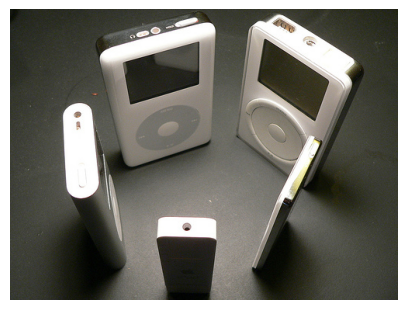

In [8]:
images = load_images(DATA_DIR, records)
example_record, example_image = next(images)
images.close()
print('Ảnh thử:', example_record)
plt.figure(figsize=(5, 5))
plt.imshow(example_image)
plt.axis('off')
plt.show()

## Bước 3 — Chọn đặc trưng cần khảo sát

| Giai đoạn tương đối | ResNet-50 V2 | ViT-B/16 V1 |
|---|---|---|
| 1 | layer1 | block 3 |
| 2 | layer2 | block 6 |
| 3 | layer3 | block 9 |
| 4 | layer4 | block 12 |

Đây là các mốc theo độ sâu, **không phải** các tầng tương đương về tính toán.
Với ResNet, lấy vector kênh ở giữa feature map, sau toàn bộ stage.
Với ViT, lấy vector của patch token ở gần tâm, sau toàn bộ block và trước
LayerNorm cuối của encoder. CLS vẫn tham gia attention nhưng không được chọn làm đầu ra.

Quy ước chỉ số bắt đầu từ 0: `row=H//2`, `col=W//2`.
Với lưới patch 14×14: chọn (7,7), token thứ `1 + 7*14 + 7 = 106` trong chuỗi có CLS.
Lưới chẵn không có duy nhất một ô tâm; vị trí receptive center giữa hai kiến trúc
cũng không trùng hoàn toàn. Notebook lưu vị trí cụ thể trong CSV.

Mỗi vector có nhiều số, cần chọn **một scalar** để backward.
Ta dùng $z=\frac{1}{C}\sum_k f_k^2$ (năng lượng trung bình của vector),
cùng quy tắc cho cả hai model. Đây là một lựa chọn thực nghiệm có chủ đích;
kết quả phụ thuộc lựa chọn scalar và không phải chuẩn toàn bộ Jacobian.
Không dùng trung bình kênh sau LayerNorm vì có thể gần hằng số và triệt tiêu gradient.

## Bước 4 — Từ gradient thành bản đồ ERF

Với $u$ là RGB trong [0,1] **sau resize/crop**, ta đo:

$$ E_{ij}=\sum_{c=1}^3\left|\frac{\partial z}{\partial u_{cij}}\right|,
   \qquad P_{ij}=E_{ij}/\sum_{ab}E_{ab}. $$

`requires_grad_(True)` yêu cầu PyTorch theo dõi ảnh đầu vào;
`autograd.grad(z, x)` tính độ nhạy của scalar với từng pixel.
`eval()` tắt dropout và dùng BatchNorm đã học, vẫn cho phép gradient.
Không bọc ERF trong `inference_mode()`.

Model nhận $x_c=(u_c-\mu_c)/\sigma_c$, nên phải chia gradient theo $x_c$
cho $\sigma_c$ để đổi về gradient theo RGB. Ta không tính đạo hàm ngược
qua phép resize/crop về ảnh gốc. Gradient thô được lưu riêng; bản đồ chuẩn hóa
mô tả phân bố tương đối. Tổng gradient thô không dùng để xếp hạng hai kiến trúc.

Đây là phép đo độ nhạy cục bộ của biểu diễn, không chứng minh pixel đó gây ra
quyết định phân loại. Cách scalar hóa và trị tuyệt đối là lựa chọn của notebook,
không phải sao chép nguyên xi mọi thiết lập của Luo et al. (2016).

In [9]:
def center_features(model, model_name, x):
    """Return center vectors AFTER each complete residual stage/block."""
    features = {}
    positions = {}
    if model_name == "resnet50":
        h = model.maxpool(model.relu(model.bn1(model.conv1(x))))
        for name in LAYERS[model_name]:
            h = getattr(model, name)(h)
            row, col = h.shape[-2] // 2, h.shape[-1] // 2
            features[name] = h[0, :, row, col]
            positions[name] = {"grid_row": row, "grid_col": col,
                               "grid_height": h.shape[-2], "grid_width": h.shape[-1],
                               "token_index": -1}
    elif model_name == "vit_b_16":
        # Match torchvision's patch embedding -> CLS -> position -> encoder path.
        # Stop before encoder.ln: channel averaging after LayerNorm is degenerate.
        h = model._process_input(x)
        grid = model.image_size // model.patch_size
        row, col = grid // 2, grid // 2
        token_index = 1 + row * grid + col  # +1 skips the CLS token.
        h = torch.cat([model.class_token.expand(x.shape[0], -1, -1), h], dim=1)
        h = model.encoder.dropout(h + model.encoder.pos_embedding)
        for depth, block in enumerate(model.encoder.layers, start=1):
            h = block(h)
            name = f"block{depth}"
            if name in LAYERS[model_name]:
                features[name] = h[0, token_index, :]
                positions[name] = {"grid_row": row, "grid_col": col,
                                   "grid_height": grid, "grid_width": grid,
                                   "token_index": token_index}
    else:
        raise ValueError(f"Unsupported model: {model_name}")
    return features, positions


@torch.enable_grad()
def compute_erf(model, model_name, normalized_image, std):
    """Differentiate center feature energy with respect to RGB crop in [0,1]."""
    if torch.is_inference_mode_enabled():
        raise RuntimeError("Run ERF outside torch.inference_mode().")
    if normalized_image.shape != (1, 3, 224, 224):
        raise ValueError("Expected one normalized RGB image: [1, 3, 224, 224].")
    if len(std) != 3 or any(value <= 0 for value in std):
        raise ValueError("Expected three positive RGB normalization std values.")
    model.eval()  # Disable dropout; use saved BatchNorm statistics.
    x = normalized_image.detach().clone().requires_grad_(True)
    features, positions = center_features(model, model_name, x)
    scale = x.new_tensor(std).view(1, 3, 1, 1)
    maps = {}
    for stage, (name, vector) in enumerate(features.items(), start=1):
        # One explicit scalar for both architectures. This is a sensitivity probe,
        # not an exact all-channel Jacobian norm or a class attribution.
        z = vector.square().mean()
        gradient = torch.autograd.grad(
            z, x, retain_graph=stage < len(features), create_graph=False,
        )[0]
        # x_norm=(RGB-mean)/std, so dz/dRGB = (dz/dx_norm)/std.
        raw = (gradient / scale).abs().sum(dim=1)[0].detach().cpu().numpy()
        raw = raw.astype(np.float32)
        if not np.isfinite(raw).all() or float(raw.sum()) <= 0:
            raise ValueError(f"Zero or non-finite gradient for {model_name}/{name}.")
        maps[name] = {"raw": raw, "stage": stage, "target_value": z.item(),
                      **positions[name]}
    return maps

## Bước 5 — Đo ERF bằng số, không chỉ nhìn màu

- **A50 / A90:** sắp pixel theo gradient giảm dần, lấy số pixel nhỏ nhất chứa
  ít nhất 50% / 90% tổng gradient rồi chia cho 224×224. Pixel có thể rời nhau;
  đây không phải bán kính, bounding box hay diện tích vùng liên thông.
- **Dispersion:** khoảng cách RMS tới trọng tâm phân bố gradient, dùng tọa độ
  x,y chuẩn hóa [0,1]. Cao hơn nghĩa là ảnh hưởng phân tán xa trọng tâm hơn.
- **Center / outer energy:** tỷ lệ gradient trong / ngoài hình vuông giữa ảnh,
  có cạnh bằng nửa chiều ảnh. Tâm ở đây là tâm ảnh, không phải vị trí feature.

Ví dụ minh họa: gradient đều trên toàn ảnh → A90 gần 90%; gradient chỉ tại
một pixel → A90 bằng 1/(224×224). Không suy ra model nào tốt hơn từ A90.

In [10]:
def erf_metrics(raw):
    """Area = smallest NUMBER of pixels reaching a fraction of absolute gradient."""
    raw = np.asarray(raw, dtype=np.float64)
    if raw.ndim != 2 or not np.isfinite(raw).all() or (raw < 0).any() or raw.sum() <= 0:
        raise ValueError("ERF must be a finite, nonnegative 2D map with positive sum.")
    p = raw / raw.sum()
    ranked = np.sort(p.ravel())[::-1]
    cumulative = np.cumsum(ranked)

    def area(q):
        count = min(np.searchsorted(cumulative, q, side="left") + 1, p.size)
        return float(count / p.size)

    yy, xx = np.indices(p.shape, dtype=np.float64)
    yy /= max(p.shape[0] - 1, 1)
    xx /= max(p.shape[1] - 1, 1)
    cy, cx = (p * yy).sum(), (p * xx).sum()
    dispersion = np.sqrt((p * ((yy - cy) ** 2 + (xx - cx) ** 2)).sum())
    # Central square occupies the middle half along each axis (~25% area).
    center = (np.abs(yy - 0.5) <= 0.25) & (np.abs(xx - 0.5) <= 0.25)
    center_energy = p[center].sum()
    return {
        "area50_fraction": area(0.5), "area90_fraction": area(0.9),
        "dispersion_normalized": float(dispersion),
        "center_energy_fraction": float(center_energy),
        "outer_energy_fraction": float(1 - center_energy),
        "centroid_y": float(cy), "centroid_x": float(cx),
        "raw_gradient_sum": float(raw.sum()),
    }

In [11]:
# Chỉ kiểm tra định nghĩa metric bằng mảng giả, không phải kết quả ImageNet.
uniform = np.ones((10, 10))
point = np.zeros((10, 10))
point[5, 5] = 1
print('Đều trên 100 pixel → A90:', erf_metrics(uniform)['area90_fraction'])
print('Tập trung 1/100 pixel → A90:', erf_metrics(point)['area90_fraction'])

Đều trên 100 pixel → A90: 0.9
Tập trung 1/100 pixel → A90: 0.01


In [12]:
def plot_image_maps(image_id, previews, destination=None):
    """Show each model's own crop and four ERF maps; color is log10 probability."""
    fig, axes = plt.subplots(2, 5, figsize=(16, 6), constrained_layout=True)
    for row, model_name in enumerate(LAYERS):
        crop, maps = previews[model_name]
        axes[row, 0].imshow(crop)
        axes[row, 0].set_title(f"{model_name}: RGB crop")
        for col, (layer, result) in enumerate(maps.items(), start=1):
            raw = result["raw"]
            probability = raw / raw.sum()
            heat = axes[row, col].imshow(
                np.log10(probability + 1e-12), cmap="magma", vmin=-8, vmax=-2,
                interpolation="nearest",
            )
            area90 = erf_metrics(raw)["area90_fraction"]
            axes[row, col].set_title(f"{layer}\nA90 = {area90:.1%}")
        for axis in axes[row]:
            axis.axis("off")
    fig.colorbar(heat, ax=axes[:, 1:].ravel().tolist(), shrink=0.7,
                 label="log10(normalized absolute gradient + 1e-12)")
    fig.suptitle(image_id)
    if destination is not None:
        fig.savefig(destination, dpi=160)
    return fig


def plot_summary(metrics, destination=None):
    """Error bars are across-image standard deviations, not confidence intervals."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    for model_name, group in metrics.groupby("model", sort=False):
        grouped = group.groupby("stage")
        for axis, metric, title in zip(
            axes, ["area90_fraction", "dispersion_normalized"],
            ["Smallest pixel area containing 90% gradient mass", "Spatial dispersion"],
        ):
            mean = grouped[metric].mean()
            sd = grouped[metric].std().fillna(0)
            axis.errorbar(mean.index, mean, yerr=sd, marker="o", capsize=3,
                          label=model_name)
            axis.set(title=title, xlabel="Relative stage (not equivalent layers)",
                     xticks=[1, 2, 3, 4])
            axis.grid(alpha=0.2)
            axis.legend()
    axes[0].set_ylabel("Fraction of input pixels (mean ± SD)")
    axes[1].set_ylabel("Normalized-coordinate RMS distance (mean ± SD)")
    if destination is not None:
        fig.savefig(destination, dpi=160)
    return fig

## Bước 6 — Định nghĩa runner và chạy một ảnh nếu cần kiểm tra lại

Ô helper dưới dùng `src.models.load_model` để nhận model, official transform và metadata.
`eval()` vẫn cho phép gradient. Đóng băng trọng số không ngăn gradient theo đầu vào.
Không đi qua `src.evaluation.evaluate`, `inference_mode` hoặc `no_grad` để tính ERF.

Trong `official`, ResNet dùng resize 232 và ViT 256, cùng center crop 224.
Trong `shared_vit_crop`, dùng chính official transform do loader trả về cho ViT cho cả hai model.
Đây là thí nghiệm nhạy với preprocessing riêng, không thay cấu hình baseline chính.

Kết quả mới dùng run ID duy nhất: CSV/JSON trong `results/metrics/experiments/erf/<run_id>/final/`,
figures trong `results/figures/experiments/erf/<run_id>/final/`.
Raw maps preview và checkpoint CSV nằm trong `intermediate/`, không đưa vào `final/`.

In [13]:
def run_experiment(records, data_dir, output_dir, device, seed=42,
                   preprocessing="official", num_previews=3, *, project_root,
                   allow_download=False, save_raw_maps=False):
    """Use shared model/data APIs; save ERF CSV/JSON and figures under final/."""
    if preprocessing not in {"official", "shared_vit_crop"}:
        raise ValueError("preprocessing must be official or shared_vit_crop.")
    if torch.is_inference_mode_enabled():
        raise RuntimeError("Run ERF outside torch.inference_mode().")
    records = list(records)
    if not records or len({r["image_id"] for r in records}) != len(records):
        raise ValueError("Provide a nonempty cohort with unique IDs.")
    if not isinstance(num_previews, int) or not 0 <= num_previews <= len(records):
        raise ValueError("num_previews must be between zero and the cohort size.")
    root, output = Path(project_root), Path(output_dir)
    expected, figure_dir, intermediate = erf_output_paths(root, output.parent.name)
    if output.resolve() != expected.resolve():
        raise ValueError(f"Use the protocol metrics directory: {expected}")
    # A lightweight probe; the main loops below always exhaust the shared iterator.
    loader = load_images(data_dir, records[:1])
    try:
        next(loader)
    finally:
        loader.close()
    if output.exists() or figure_dir.exists() or intermediate.exists():
        raise FileExistsError("Run ID already exists; choose a new run_id.")
    output.mkdir(parents=True, exist_ok=False)
    figure_dir.mkdir(parents=True, exist_ok=False)
    intermediate.mkdir(parents=True, exist_ok=False)
    maps_dir = intermediate / "maps"
    maps_dir.mkdir()
    pd.DataFrame(records).to_csv(output / "selected_images.csv", index=False)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    config = json.loads((root / "configs/analysis_set.json").read_text("utf-8"))
    manifest = root / config["manifest"]
    preview_ids = {row["image_id"] for row in random.Random(seed).sample(records, num_previews)}
    metadata = {
        "experiment": "erf", "run_id": output.parent.name,
        "status": "running", "num_images": len(records), "seed": seed,
        "device": str(device), "torch": torch.__version__,
        "torchvision": torchvision.__version__, "numpy": np.__version__, "pandas": pd.__version__,
        "preprocessing": preprocessing, "condition": preprocessing, "severity": "",
        "batch_size": 1, "allow_download": allow_download,
        "target": "mean(square(center_feature_vector)); post-stage/post-block, pre-final-LN",
        "center_rule": "row=grid_height//2, col=grid_width//2; zero-based",
        "gradient_coordinates": "RGB [0,1] AFTER resize/crop, BEFORE normalization",
        "layers": LAYERS, "models": {}, "exclusions": [],
        "selection_rule": "random.Random(seed).sample(ID-sorted shared manifest, N); no correctness filtering",
        "cohort_kind": "full_analysis_set" if len(records) == config["num_images"] else "pilot_subset",
        "manifest": str(manifest),
        "manifest_sha256": hashlib.sha256(manifest.read_bytes().replace(b"\r\n", b"\n")).hexdigest(),
        "selected_images_sha256": hashlib.sha256((output / "selected_images.csv").read_bytes()).hexdigest(),
        "cohort_sha256_lf": hashlib.sha256((output / "selected_images.csv").read_bytes().replace(b"\r\n", b"\n")).hexdigest(),
        "preview_ids": sorted(preview_ids), "raw_maps": "all" if save_raw_maps else "previews_only",
        "metrics_dir": str(output), "figures_dir": str(figure_dir),
        "code": erf_code_provenance(root),
        "metric_units": {"area50_fraction": "fraction of input pixels", "area90_fraction": "fraction of input pixels",
                         "dispersion_normalized": "normalized-coordinate RMS distance"},
    }
    metadata_path = output / "metadata.json"
    def save_metadata():
        metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    save_metadata()
    rows, previews, model, vit_transform = [], {}, None, None
    try:
        # ViT first provides its official transform for the common-view sensitivity run.
        for model_name in ("vit_b_16", "resnet50"):
            model, official_transform, model_metadata = load_model(
                model_name, device=device, allow_download=allow_download,
            )
            if model_name == "vit_b_16":
                vit_transform = official_transform
            transform = vit_transform if preprocessing == "shared_vit_crop" else official_transform
            metadata["models"][model_name] = {
                "weights": model_metadata["weights"], "transform": repr(transform),
                "baseline_loader": model_metadata,
            }
            save_metadata()
            model.requires_grad_(False)  # Input gradients remain enabled; no training.
            for record, image in tqdm(load_images(data_dir, records), total=len(records), desc=model_name):
                x = transform(image).unsqueeze(0).to(device)
                maps = compute_erf(model, model_name, x, transform.std)
                image_id = record["image_id"]
                if save_raw_maps or image_id in preview_ids:
                    np.savez_compressed(maps_dir / f"{model_name}_{record['dataset_index']:05d}.npz",
                                        **{name: result["raw"] for name, result in maps.items()})
                for layer, result in maps.items():
                    rows.append({**record, "model": model_name, "model_name": model_name,
                                 "experiment": "erf", "run_id": output.parent.name,
                                 "condition": preprocessing, "severity": "", "layer": layer,
                                 **{k: v for k, v in result.items() if k != "raw"},
                                 **erf_metrics(result["raw"])})
                if image_id in preview_ids:
                    rgb = (x[0].detach().cpu() * torch.tensor(transform.std)[:, None, None]
                           + torch.tensor(transform.mean)[:, None, None])
                    previews.setdefault(image_id, {})[model_name] = (
                        rgb.permute(1, 2, 0).clamp(0, 1).numpy(), maps)
                # Partial metrics stay outside final until both model loops finish.
                pd.DataFrame(rows).to_csv(intermediate / "metrics_checkpoint.csv", index=False)
                del x, maps
            del model
            model = None
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        metrics = pd.DataFrame(rows)
        if len(metrics) != len(records) * 8 or metrics.duplicated(["image_id", "model", "stage"]).any():
            raise ValueError("Expected 8 unique image/model/stage rows per selected image.")
        metrics.to_csv(output / "metrics.csv", index=False)
        summary = metrics.groupby(["model", "stage", "layer"])[[
            "area50_fraction", "area90_fraction", "dispersion_normalized",
            "center_energy_fraction", "outer_energy_fraction",
        ]].agg(["mean", "std", "count"])
        summary.to_csv(output / "summary.csv")
        caption = f"{preprocessing}; ResNet50 V2 / ViT-B16 V1; target: center-feature mean-square energy"
        for index, (image_id, preview) in enumerate(previews.items()):
            fig = plot_image_maps(image_id, preview)
            fig.suptitle(f"{image_id}\n{caption}", fontsize=10)
            fig.savefig(figure_dir / f"image_{index:02d}.png", dpi=160)
            plt.close(fig)
        fig = plot_summary(metrics)
        fig.suptitle(caption, fontsize=9)
        fig.savefig(figure_dir / "comparison.png", dpi=160)
        plt.close(fig)
        metadata["status"] = "complete"
        save_metadata()
        return metrics, summary, previews
    except Exception as error:
        metadata.update(status="failed", error=str(error))
        save_metadata()
        raise
    finally:
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

In [15]:
ALLOW_DOWNLOAD = True

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 172MB/s]


vit_b_16:   0%|          | 0/1 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 149MB/s]


resnet50:   0%|          | 0/1 [00:00<?, ?it/s]

,model,layer,grid_row,grid_col,token_index,area50_fraction,area90_fraction,dispersion_normalized
0,vit_b_16,block3,7,7,106,0.014808,0.250299,0.274466
1,vit_b_16,block6,7,7,106,0.055724,0.377412,0.297511
2,vit_b_16,block9,7,7,106,0.079102,0.432537,0.347808
3,vit_b_16,block12,7,7,106,0.091558,0.448780,0.377693
4,resnet50,layer1,28,28,-1,0.001535,0.006437,0.031359
5,resnet50,layer2,14,14,-1,0.007254,0.034558,0.072292
6,resnet50,layer3,7,7,-1,0.041693,0.223513,0.182936
7,resnet50,layer4,3,3,-1,0.129285,0.537946,0.301726


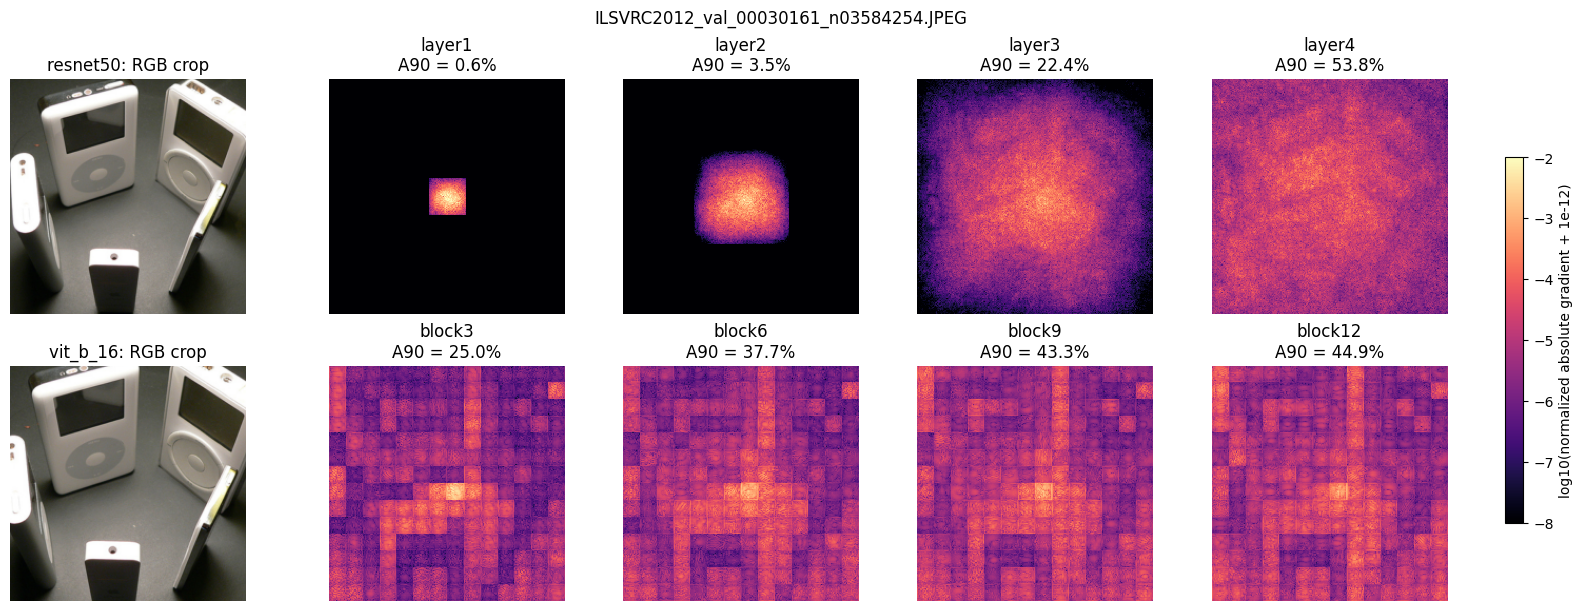

Metrics: /content/drive/MyDrive/cnn-vit-interpretability/results/metrics/experiments/erf/smoke_1_official_20261103T145222_781371Z/final
Figures: /content/drive/MyDrive/cnn-vit-interpretability/results/figures/experiments/erf/smoke_1_official_20261103T145222_781371Z/final


In [16]:
from datetime import datetime, timezone

def new_run_dir(name, preprocessing='official'):
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    return erf_output_paths(PROJECT_ROOT, f'{name}_{preprocessing}_{stamp}')[0]

smoke_dir = new_run_dir('smoke_1')
smoke_metrics, smoke_summary, smoke_previews = run_experiment(
    records[:1], DATA_DIR, smoke_dir, DEVICE,
    seed=SEED, preprocessing='official', num_previews=1,
    project_root=PROJECT_ROOT, allow_download=ALLOW_DOWNLOAD,
)
display(smoke_metrics[['model', 'layer', 'grid_row', 'grid_col', 'token_index',
                       'area50_fraction', 'area90_fraction', 'dispersion_normalized']])
fig = plot_image_maps(records[0]['image_id'], smoke_previews[records[0]['image_id']])
plt.show()
print('Metrics:', smoke_dir)
print('Figures:', erf_output_paths(PROJECT_ROOT, smoke_dir.parent.name)[1])

**Trước khi chạy nhiều ảnh:** xác nhận có 8 dòng metrics (2 model × 4 tầng),
gradient hữu hạn và tổng dương, A50 ≤ A90 ≤ 1. Nếu lỗi thiếu shard, quay lại
bước 1. Nếu GPU hết bộ nhớ, khởi động lại runtime để giải phóng model còn sót
từ các lần chạy trước; notebook đã dùng từng ảnh và từng model.

Không kết luận xu hướng từ một ảnh. Ta chuyển sang nhiều ảnh để tính phân bố.

In [17]:
assert len(smoke_metrics) == 8
assert np.isfinite(smoke_metrics['raw_gradient_sum']).all()
assert (smoke_metrics['raw_gradient_sum'] > 0).all()
assert (smoke_metrics['area50_fraction'] <= smoke_metrics['area90_fraction']).all()
assert smoke_metrics['area90_fraction'].between(0, 1).all()
print('Kiểm tra một ảnh đạt. Có thể chuyển sang tập nhỏ.')

Kiểm tra một ảnh đạt. Có thể chuyển sang tập nhỏ.


## Bước 7 — Chạy official trên 100 ảnh nếu chưa có run hoàn chỉnh

Ô dưới là lượt `official` đã chạy, có 800 dòng metrics (100 ảnh × 2 model × 4 tầng).
Nếu thư mục run cũ trên Drive vẫn còn `run.json`, `selected_images.csv`, `metrics.csv`,
**bỏ qua ô chạy này và sang Bước 8a**. Bước 8a sẽ kiểm tra rồi nạp lại số liệu cũ.
Nếu cần tạo run mới, giữ `PREPROCESSING = 'official'` và chạy ô dưới.

CSV tính metric trên từng ảnh rồi tổng hợp; thanh sai số hiện tại là SD giữa ảnh,
không phải khoảng tin cậy. Các khoảng tin cậy bootstrap được bổ sung ở Bước 8c.

vit_b_16:   0%|          | 0/100 [00:00<?, ?it/s]

resnet50:   0%|          | 0/100 [00:00<?, ?it/s]

area50_fraction                 area90_fraction  \
                                  mean       std count            mean   
model    stage layer                                                     
resnet50 1     layer1         0.001520  0.000218   100        0.006487   
         2     layer2         0.006201  0.001169   100        0.029298   
         3     layer3         0.042383  0.011135   100        0.235884   
         4     layer4         0.132522  0.027495   100        0.529602   
vit_b_16 1     block3         0.022824  0.013938   100        0.398192   
         2     block6         0.081890  0.028947   100        0.497341   
         3     block9         0.111998  0.033218   100        0.542757   
         4     block12        0.105799  0.029000   100        0.533151   

                                       dispersion_normalized                  \
                             std count                  mean       std count   
model    stage layer                                                           
resnet50 1     layer1   0.000605   100              0.030991  0.001590   100   
         2     layer2   0.003556   100              0.065769  0.004406   100   
         3     layer3   0.044763   100              0.185427  0.018602   100   
         4     layer4   0.054093   100              0.304416  0.024103   100   
vit_b_16 1     block3   0.111256   100              0.277713  0.030803   100   
         2     block6   0.077678   100              0.314316  0.030750   100   
         3     block9   0.066689   100              0.344022  0.035005   100   
         4     block12  0.063507   100              0.353807  0.035485   100   

                       center_energy_fraction                      \
                                         mean           std count   
model    stage layer                                                
resnet50 1     layer1                1.000000  5.797951e-17   100   
         2     layer2                1.000000  8.570746e-17   100   
         3     layer3                0.864896  4.318973e-02   100   
         4     layer4                0.527835  7.449179e-02   100   
vit_b_16 1     block3                0.652978  7.409300e-02   100   
         2     block6                0.556872  8.429681e-02   100   
         3     block9                0.468305  9.778682e-02   100   
         4     block12               0.430719  1.075504e-01   100   

                       outer_energy_fraction                      
                                        mean           std count  
model    stage layer                                              
resnet50 1     layer1           5.551115e-18  5.771046e-17   100  
         2     layer2           1.221245e-17  8.482405e-17   100  
         3     layer3           1.351036e-01  4.318973e-02   100  
         4     layer4           4.721653e-01  7.449179e-02   100  
vit_b_16 1     block3           3.470225e-01  7.409300e-02   100  
         2     block6           4.431276e-01  8.429681e-02   100  
         3     block9           5.316947e-01  9.778682e-02   100  
         4     block12          5.692814e-01  1.075504e-01   100

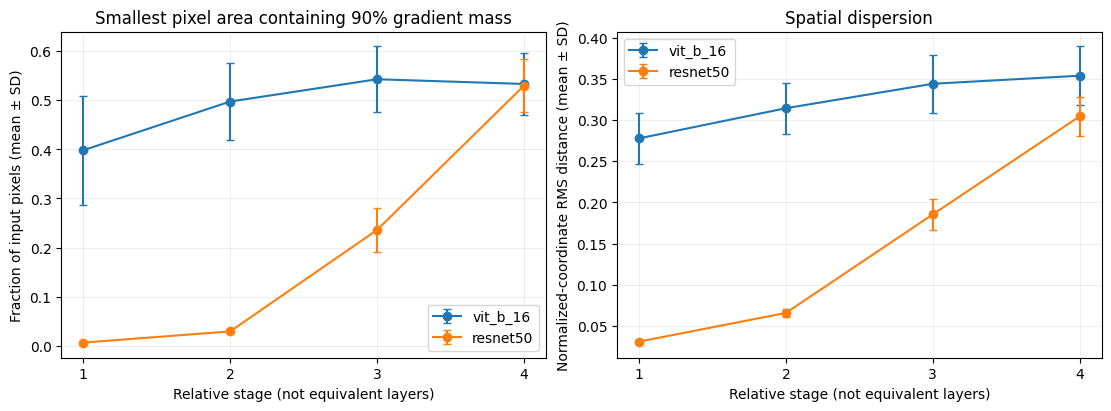

Official hoàn tất: /content/drive/MyDrive/cnn-vit-interpretability/results/metrics/experiments/erf/main_100_official_20261103T145742_031867Z/final
Figures: /content/drive/MyDrive/cnn-vit-interpretability/results/figures/experiments/erf/main_100_official_20261103T145742_031867Z/final
Số dòng metrics: 800 | Mong đợi: 800


In [18]:
from datetime import datetime, timezone
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
run_dir = erf_output_paths(PROJECT_ROOT, f'main_100_official_{stamp}')[0]
metrics, summary, previews = run_experiment(
    records, DATA_DIR, run_dir, DEVICE,
    seed=SEED, preprocessing='official', num_previews=3,
    project_root=PROJECT_ROOT, allow_download=ALLOW_DOWNLOAD,
)
display(summary)
fig = plot_summary(metrics)
plt.show()
print('Official hoàn tất:', run_dir)
print('Figures:', erf_output_paths(PROJECT_ROOT, run_dir.parent.name)[1])
print('Số dòng metrics:', len(metrics), '| Mong đợi:', 8 * len(records))

## Bước 8 — Đọc và viết kết quả

Bảng dưới so sánh trên **cùng từng ảnh**, với chênh lệch A90 = ViT − ResNet.
Giá trị dương nghĩa là ViT cần nhiều pixel hơn để chứa 90% gradient theo phép đo này.
Chỉ ghép theo giai đoạn tương đối; không khẳng định layer1 tương đương block3.

In [19]:
paired = metrics.pivot(index=['image_id', 'stage'], columns='model', values='area90_fraction')
paired['vit_minus_resnet_pp'] = 100 * (paired['vit_b_16'] - paired['resnet50'])
paired_summary = paired.groupby('stage')['vit_minus_resnet_pp'].agg(['mean', 'std', 'count'])
paired_summary.to_csv(run_dir / 'paired_area90_difference.csv')
display(paired_summary)

,mean,std,count
stage,,,
1,39.170480,11.127155,100
2,46.804289,7.736552,100
3,30.687341,5.631317,100
4,0.354911,6.613632,100


## Bước 8a — Nạp lại official và chuẩn bị kiểm định

Dùng đúng 100 ảnh, ghép theo `image_id` và giai đoạn tương đối. Không coi 800 dòng
metrics là 800 quan sát độc lập: mỗi phép so sánh chỉ có **100 cặp ảnh**.

- **Hiệu số:** ViT − ResNet. A90 đổi sang **điểm phần trăm**; dispersion giữ đơn vị RMS
  theo tọa độ chuẩn hóa. So sánh 4 giai đoạn tương đối, không coi các tầng là tương đương.
- **Wilcoxon signed-rank hai phía:** kiểm tra phân bố hiệu số đối xứng quanh 0;
  phép diễn giải như kiểm định vị trí cần giả định đối xứng. Không phải kiểm định
  trực tiếp trung bình; p-value không đo độ lớn khác biệt.
- **Bootstrap ghép cặp:** lấy mẫu lại 100 hiệu số theo ảnh, 20.000 lần, seed cố định,
  để ước lượng CI percentile 95% của **trung bình hiệu số**. Không lấy mẫu hai model riêng.
- **Holm:** hiệu chỉnh chung 16 p-value (2 crop × 2 metric × 4 giai đoạn), ngưỡng 0,05.
  CI bootstrap là CI riêng từng so sánh, chưa hiệu chỉnh đa kiểm định. Dựa vào `p_holm`
  khi nói về ý nghĩa thống kê trong họ 16 phép kiểm định.
- Không bỏ cặp thiếu/NaN; nếu thiếu ảnh, trùng dòng, sai nhãn hoặc run chưa `complete`, dừng.
  Hiệu số được làm tròn 12 chữ số thập phân trước Wilcoxon; toàn bộ bằng 0 cho p = 1.

Ô helper dưới chứa trực tiếp toàn bộ hàm thống kê. Không cần file `erf_statistics.py`.

In [20]:
"""Phân tích ghép cặp tích hợp trực tiếp trong notebook ERF 100 ảnh."""

import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy.stats import wilcoxon


ERF_METRICS = {
    "area90_fraction": (100.0, "percentage points"),
    "dispersion_normalized": (1.0, "normalized-coordinate RMS distance"),
}
ERF_STAGE_LAYERS = {
    "resnet50": {1: "layer1", 2: "layer2", 3: "layer3", 4: "layer4"},
    "vit_b_16": {1: "block3", 2: "block6", 3: "block9", 4: "block12"},
}


def validate_erf_metrics(metrics, records):
    """Require every selected image/model/stage exactly once; never drop pairs."""
    required = {"image_id", "dataset_index", "label", "model", "stage", "layer",
                *ERF_METRICS}
    if not required.issubset(metrics.columns):
        raise ValueError(f"Missing metrics columns: {sorted(required - set(metrics.columns))}")
    selected = pd.DataFrame(records)[["image_id", "dataset_index", "label"]]
    if selected.empty or selected.isna().any().any():
        raise ValueError("Selected records must be nonempty and complete.")
    if not selected.image_id.is_unique or not selected.dataset_index.is_unique:
        raise ValueError("Selected image IDs and dataset indices must be unique.")
    keys = ["image_id", "model", "stage"]
    expected = pd.MultiIndex.from_tuples(
        [(row["image_id"], model, stage) for row in records
         for model, layers in ERF_STAGE_LAYERS.items() for stage in layers], names=keys,
    )
    actual = pd.MultiIndex.from_frame(metrics[keys])
    if not actual.is_unique or set(actual) != set(expected):
        raise ValueError("Expected exactly one row per selected image/model/stage (8 x N).")
    joined = metrics.merge(selected, on="image_id", suffixes=("", "_selected"),
                           validate="many_to_one")
    for column in ["dataset_index", "label"]:
        if not joined[column].eq(joined[f"{column}_selected"]).all():
            raise ValueError(f"Metrics {column} differs from selected images.")
    for model, layers in ERF_STAGE_LAYERS.items():
        group = metrics[metrics.model == model]
        if not group.layer.eq(group.stage.map(layers)).all():
            raise ValueError(f"Layer/stage mismatch for {model}.")
    for metric in ERF_METRICS:
        values = metrics[metric].to_numpy(dtype=float)
        if not np.isfinite(values).all() or (values < 0).any() or (values > 1).any():
            raise ValueError(f"Invalid or missing {metric} values.")
    return metrics


def load_completed_erf_run(directory, records, preprocessing, seed=42):
    """Read a completed run only if its selection, checksum and settings match."""
    directory = Path(directory)
    metadata_path = directory / "metadata.json"
    if not metadata_path.is_file():
        metadata_path = directory / "run.json"  # Legacy official runs.
    metadata = json.loads(metadata_path.read_text("utf-8"))
    if (metadata.get("status") != "complete"
            or metadata.get("num_images") != len(records)
            or metadata.get("preprocessing") != preprocessing
            or metadata.get("seed") != seed):
        raise ValueError(f"Incomplete run or incompatible settings: {directory}")
    selection_path = directory / "selected_images.csv"
    if hashlib.sha256(selection_path.read_bytes()).hexdigest() != metadata.get("selected_images_sha256"):
        raise ValueError("Saved selection checksum does not match run.json.")
    columns = ["image_id", "dataset_index", "label"]
    saved = pd.read_csv(selection_path)[columns].sort_values("image_id").reset_index(drop=True)
    wanted = pd.DataFrame(records)[columns].sort_values("image_id").reset_index(drop=True)
    pd.testing.assert_frame_equal(saved, wanted, check_dtype=False)
    metrics = pd.read_csv(directory / "metrics.csv")
    validate_erf_metrics(metrics, records)
    return metrics, metadata


def validate_erf_run_pair(official_metadata, shared_metadata):
    """The only intended experimental change is preprocessing."""
    for key in ["target", "center_rule", "gradient_coordinates", "layers", "seed", "num_images"]:
        if key not in official_metadata or official_metadata[key] != shared_metadata.get(key):
            raise ValueError(f"Runs differ in {key}; cannot attribute changes to preprocessing.")
    for model in ERF_STAGE_LAYERS:
        before = official_metadata["models"][model]
        after = shared_metadata["models"][model]
        if before["weights"] != after["weights"]:
            raise ValueError(f"Model weights differ: {model}")
    shared_models = shared_metadata["models"]
    if shared_models["resnet50"]["transform"] != shared_models["vit_b_16"]["transform"]:
        raise ValueError("shared_vit_crop must use identical transforms for both models.")
    if official_metadata["models"]["vit_b_16"]["transform"] != shared_models["vit_b_16"]["transform"]:
        raise ValueError("ViT preprocessing should be unchanged between the two runs.")


def paired_erf_differences(metrics, records, preprocessing):
    """Align by image ID and stage, independent of CSV/loader row order."""
    validate_erf_metrics(metrics, records)
    frames = []
    for metric, (scale, unit) in ERF_METRICS.items():
        paired = metrics.pivot(index=["image_id", "stage"], columns="model", values=metric)
        paired = paired.sort_index().reset_index()
        paired["difference"] = (paired["vit_b_16"] - paired["resnet50"]) * scale
        paired["metric"], paired["unit"], paired["preprocessing"] = metric, unit, preprocessing
        frames.append(paired)
    return pd.concat(frames, ignore_index=True)


def bootstrap_mean_ci(differences, seed=42, n_resamples=20000):
    """Resample images/pairs, not the two model columns separately."""
    values = np.asarray(differences, dtype=float)
    if values.ndim != 1 or len(values) < 2 or not np.isfinite(values).all():
        raise ValueError("Bootstrap requires at least two finite paired differences.")
    if not isinstance(n_resamples, (int, np.integer)) or n_resamples < 1000:
        raise ValueError("Use at least 1,000 bootstrap resamples.")
    rng = np.random.default_rng(seed)
    means = np.empty(n_resamples)
    for start in range(0, n_resamples, 1000):
        stop = min(start + 1000, n_resamples)
        indices = rng.integers(0, len(values), size=(stop - start, len(values)))
        means[start:stop] = values[indices].mean(axis=1)
    return np.quantile(means, [0.025, 0.975])


def holm_adjust(pvalues):
    """Holm family-wise error correction, preserving the original row order."""
    pvalues = np.asarray(pvalues, dtype=float)
    if pvalues.ndim != 1 or not np.isfinite(pvalues).all() or ((pvalues < 0) | (pvalues > 1)).any():
        raise ValueError("P-values must be finite numbers in [0, 1].")
    order = np.argsort(pvalues, kind="stable")
    adjusted = np.empty_like(pvalues)
    adjusted[order] = np.minimum(1, np.maximum.accumulate(
        pvalues[order] * np.arange(len(pvalues), 0, -1)))
    return adjusted


def paired_erf_tests(pairs, seed=42, n_resamples=20000):
    """Two-sided signed-rank tests; bootstrap mean CIs are separate estimates."""
    rows = []
    for group_index, ((mode, metric, stage), group) in enumerate(
        pairs.groupby(["preprocessing", "metric", "stage"], sort=True)
    ):
        group = group.sort_values("image_id")
        if not group.image_id.is_unique:
            raise ValueError("Duplicate image in a paired comparison.")
        delta = group.difference.to_numpy(dtype=float)
        low, high = bootstrap_mean_ci(delta, seed + group_index, n_resamples)
        # Round subtraction noise consistently; zeros are excluded by Wilcoxon.
        signed_rank_delta = np.round(delta, 12)
        nonzero = np.count_nonzero(signed_rank_delta)
        if nonzero == 0:
            statistic, pvalue = 0.0, 1.0
        else:
            result = wilcoxon(signed_rank_delta, zero_method="wilcox",
                              alternative="two-sided", method="auto")
            statistic, pvalue = float(result.statistic), float(result.pvalue)
        rows.append({
            "preprocessing": mode, "metric": metric, "stage": int(stage),
            "resnet_layer": ERF_STAGE_LAYERS["resnet50"][stage],
            "vit_layer": ERF_STAGE_LAYERS["vit_b_16"][stage],
            "n_pairs": len(delta), "n_nonzero_wilcoxon": int(nonzero),
            "unit": group.unit.iloc[0],
            "resnet_mean": group.resnet50.mean() * ERF_METRICS[metric][0],
            "vit_mean": group.vit_b_16.mean() * ERF_METRICS[metric][0],
            "mean_difference": delta.mean(), "median_difference": np.median(delta),
            "sd_difference": delta.std(ddof=1),
            "mean_ci95_low": low, "mean_ci95_high": high,
            "wilcoxon_statistic": statistic, "p_value": pvalue,
        })
    tests = pd.DataFrame(rows)
    if tests.empty:
        raise ValueError("No paired comparisons supplied.")
    # One family: 2 preprocessing modes x 2 metrics x 4 relative stages = 16.
    tests["p_holm"] = holm_adjust(tests.p_value)
    tests["reject_holm_0_05"] = tests.p_holm < 0.05
    return tests


def erf_crop_sensitivity(pairs, seed=42, n_resamples=20000):
    """Descriptive CI for change in the ViT-minus-ResNet gap on the same images."""
    wide = pairs.pivot(index=["image_id", "metric", "stage", "unit"],
                       columns="preprocessing", values="difference")
    if set(wide.columns) != {"official", "shared_vit_crop"} or wide.isna().any().any():
        raise ValueError("Both preprocessing modes must contain exactly the same image pairs.")
    wide["gap_change"] = wide.shared_vit_crop - wide.official
    rows = []
    for index, ((metric, stage, unit), group) in enumerate(wide.reset_index().groupby(
        ["metric", "stage", "unit"], sort=True
    )):
        group = group.sort_values("image_id")
        delta = group.gap_change.to_numpy()
        low, high = bootstrap_mean_ci(delta, seed + index, n_resamples)
        rows.append({"metric": metric, "stage": int(stage), "unit": unit,
                     "n_pairs": len(delta), "official_gap_mean": group.official.mean(),
                     "shared_gap_mean": group.shared_vit_crop.mean(),
                     "gap_change_mean": delta.mean(), "mean_ci95_low": low,
                     "mean_ci95_high": high})
    return pd.DataFrame(rows)

In [21]:
# Nếu vừa chạy Bước 7, dùng run_dir của lượt mới. Nếu không, dùng run đã có trên Drive.
OFFICIAL_RUN_DIR = Path(globals().get(
    'run_dir', LEGACY_OUTPUT_BASE / 'main_100_official_20261103T092649_717108Z'
))
if NUM_IMAGES != 100 or len(records) != 100:
    raise ValueError('Notebook này yêu cầu đúng 100 ảnh. Chạy lại ô chọn records ở Bước 2.')
if SEED != 42:
    raise ValueError('Dùng seed 42 để khớp danh sách ảnh của run official đã lưu.')
if not any((OFFICIAL_RUN_DIR / name).is_file() for name in ['metadata.json', 'run.json']):
    raise FileNotFoundError(
        f'Không tìm thấy run official: {OFFICIAL_RUN_DIR}. '
        'Sửa OFFICIAL_RUN_DIR theo thư mục thật trên Drive, hoặc chạy Bước 7.'
    )
official_metrics, official_metadata = load_completed_erf_run(
    OFFICIAL_RUN_DIR, records, 'official', SEED,
)
official_run_dir = OFFICIAL_RUN_DIR
print('Official hợp lệ:', official_run_dir)
print('Số ảnh:', official_metrics.image_id.nunique(), '| Số dòng:', len(official_metrics))
print('SciPy:', scipy.__version__)

Official hợp lệ: /content/drive/MyDrive/cnn-vit-interpretability/results/metrics/experiments/erf/main_100_official_20261103T145742_031867Z/final
Số ảnh: 100 | Số dòng: 800
SciPy: 1.16.3


## Bước 8b — Chạy shared_vit_crop trên cùng 100 ảnh

Cả hai model dùng resize cạnh ngắn 256 → center crop 224 với cùng mean/std của ViT.
Trọng số, target, tầng, seed và danh sách ảnh được giữ như lượt `official`.
Chế độ này thay preprocessing chính thức của ResNet; báo cáo riêng.

Mặc định ô dưới chạy cả hai model và lưu run mới. Nếu đã chạy xong, điền đường dẫn
vào `SHARED_RUN_DIR` để nạp lại; run thiếu/hỏng sẽ báo lỗi, không tự dùng kết quả dở dang.
Biến `PREPROCESSING` không cần đổi: tham số `preprocessing='shared_vit_crop'` được truyền rõ ràng.

vit_b_16:   0%|          | 0/100 [00:00<?, ?it/s]

resnet50:   0%|          | 0/100 [00:00<?, ?it/s]

Shared crop hợp lệ: /content/drive/MyDrive/cnn-vit-interpretability/results/metrics/experiments/erf/main_100_shared_vit_crop_20261103T150143_831384Z/final
Số ảnh: 100 | Số dòng: 800


area90_fraction                 dispersion_normalized  \
                                  mean       std count                  mean   
model    stage layer                                                           
resnet50 1     layer1         0.006482  0.000576   100              0.030974   
         2     layer2         0.029483  0.003798   100              0.066072   
         3     layer3         0.242476  0.043569   100              0.187926   
         4     layer4         0.535210  0.053001   100              0.306531   
vit_b_16 1     block3         0.398192  0.111256   100              0.277713   
         2     block6         0.497341  0.077678   100              0.314316   
         3     block9         0.542757  0.066689   100              0.344022   
         4     block12        0.533151  0.063507   100              0.353807   

                                        
                             std count  
model    stage layer                    
resnet50 1     layer1   0.001568   100  
         2     layer2   0.004711   100  
         3     layer3   0.017945   100  
         4     layer4   0.023649   100  
vit_b_16 1     block3   0.030803   100  
         2     block6   0.030750   100  
         3     block9   0.035005   100  
         4     block12  0.035485   100

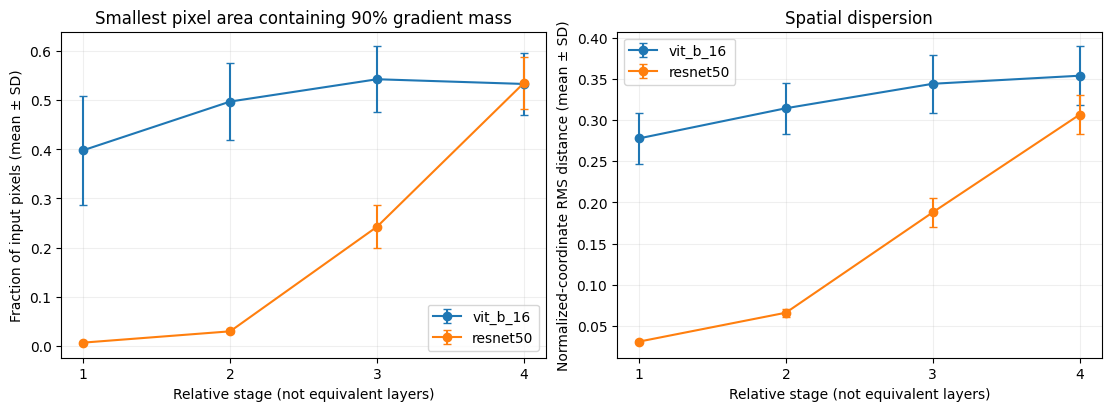

In [22]:
from datetime import datetime, timezone

# None: tạo lượt mới. Hoặc Path('/content/drive/.../main_100_shared_vit_crop_.../final') để nạp lại.
SHARED_RUN_DIR = None

if SHARED_RUN_DIR is None:
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    shared_run_dir = erf_output_paths(PROJECT_ROOT, f'main_100_shared_vit_crop_{stamp}')[0]
    shared_metrics, shared_summary, shared_previews = run_experiment(
        records, DATA_DIR, shared_run_dir, DEVICE,
        seed=SEED, preprocessing='shared_vit_crop', num_previews=3,
        project_root=PROJECT_ROOT, allow_download=ALLOW_DOWNLOAD,
    )
else:
    shared_run_dir = Path(SHARED_RUN_DIR)

# Nạp lại từ đĩa: xác nhận chính các CSV đã lưu, không chỉ biến còn trong kernel.
shared_metrics, shared_metadata = load_completed_erf_run(
    shared_run_dir, records, 'shared_vit_crop', SEED,
)
validate_erf_run_pair(official_metadata, shared_metadata)
print('Shared crop hợp lệ:', shared_run_dir)
print('Số ảnh:', shared_metrics.image_id.nunique(), '| Số dòng:', len(shared_metrics))
display(shared_metrics.groupby(['model', 'stage', 'layer'])[
    ['area90_fraction', 'dispersion_normalized']
].agg(['mean', 'std', 'count']))
fig = plot_summary(shared_metrics)
plt.show()

## Bước 8c — Kiểm định, CI và độ nhạy với preprocessing

`paired_tests.csv` có 16 hàng. `mean_difference` và CI dùng đơn vị ở cột `unit`.
`reject_holm_0_05` dựa vào p-value đã hiệu chỉnh. Dấu dương nghĩa là ViT có metric lớn hơn;
không suy ra model tốt hơn, và không kết luận từ mỗi p-value.

`crop_sensitivity.csv` đo trên từng ảnh: **(ViT − ResNet)shared − (ViT − ResNet)official**.
CI ở bảng này chỉ mang tính mô tả, không thêm một họ kiểm định mới. Xem độ lớn,
dấu và độ bất định để đánh giá mức phụ thuộc preprocessing; CI chứa 0 không chứng minh
hai thiết lập tương đương. Chạy chung crop cũng không loại bỏ khác biệt huấn luyện/trọng số.

Các bảng/biểu đồ dưới chỉ có sau khi hai lượt thực sự hoàn tất. Số liệu tổng hợp
cũ không đủ để suy ra Wilcoxon hay bootstrap: cần CSV metric từng ảnh.

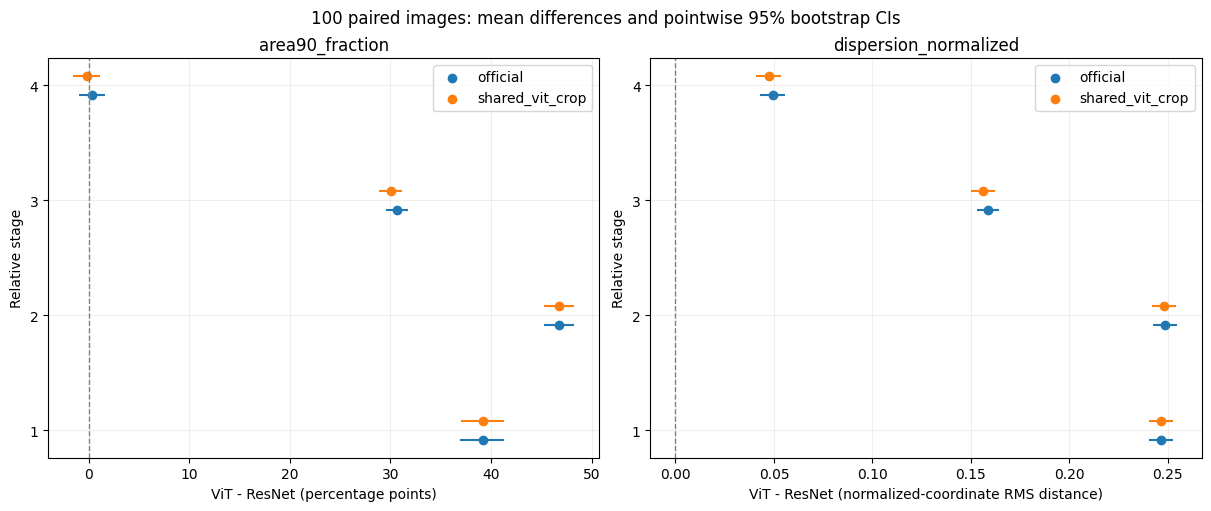

,preprocessing,metric,stage,resnet_layer,vit_layer,n_pairs,n_nonzero_wilcoxon,unit,resnet_mean,vit_mean,mean_difference,median_difference,sd_difference,mean_ci95_low,mean_ci95_high,wilcoxon_statistic,p_value,p_holm,reject_holm_0_05
0,official,area90_fraction,1,layer1,block3,100,100,percentage points,0.648697,39.819176,39.170480,41.437141,11.127155,36.950288,41.302243,0.0,3.896560e-18,6.234144e-17,True
1,official,area90_fraction,2,layer2,block6,100,100,percentage points,2.929847,49.734136,46.804289,48.644770,7.736552,45.276285,48.293758,0.0,3.896560e-18,6.234144e-17,True
2,official,area90_fraction,3,layer3,block9,100,100,percentage points,23.588389,54.275729,30.687341,30.674027,5.631317,29.592791,31.784988,0.0,3.896340e-18,6.234144e-17,True
3,official,area90_fraction,4,layer4,block12,100,100,percentage points,52.960180,53.315091,0.354911,0.635762,6.613632,-0.949601,1.621236,2293.0,4.250496e-01,8.500992e-01,False
4,official,dispersion_normalized,1,layer1,block3,100,100,normalized-coordinate RMS distance,0.030991,0.277713,0.246722,0.250009,0.030885,0.240613,0.252652,0.0,3.896560e-18,6.234144e-17,True
5,official,dispersion_normalized,2,layer2,block6,100,100,normalized-coordinate RMS distance,0.065769,0.314316,0.248547,0.250448,0.030827,0.242505,0.254419,0.0,3.896560e-18,6.234144e-17,True
6,official,dispersion_normalized,3,layer3,block9,100,100,normalized-coordinate RMS distance,0.185427,0.344022,0.158596,0.158782,0.029252,0.152922,0.164242,0.0,3.896560e-18,6.234144e-17,True
7,official,dispersion_normalized,4,layer4,block12,100,100,normalized-coordinate RMS distance,0.304416,0.353807,0.049391,0.049018,0.032807,0.043010,0.055759,81.0,4.342299e-17,1.736920e-16,True
8,shared_vit_crop,area90_fraction,1,layer1,block3,100,100,percentage points,0.648218,39.819176,39.170958,41.451092,11.128530,36.985759,41.320838,0.0,3.896560e-18,6.234144e-17,True
9,shared_vit_crop,area90_fraction,2,layer2,block6,100,100,percentage points,2.948342,49.734136,46.785794,48.674665,7.737992,45.249789,48.271328,0.0,3.896560e-18,6.234144e-17,True


,metric,stage,unit,n_pairs,official_gap_mean,shared_gap_mean,gap_change_mean,mean_ci95_low,mean_ci95_high
0,area90_fraction,1,percentage points,100,39.170480,39.170958,0.000478,-0.007016,0.007693
1,area90_fraction,2,percentage points,100,46.804289,46.785794,-0.018495,-0.052993,0.016921
2,area90_fraction,3,percentage points,100,30.687341,30.028141,-0.659200,-0.999128,-0.306421
3,area90_fraction,4,percentage points,100,0.354911,-0.205955,-0.560866,-1.159772,0.048200
4,dispersion_normalized,1,normalized-coordinate RMS distance,100,0.246722,0.246740,0.000017,-0.000186,0.000220
5,dispersion_normalized,2,normalized-coordinate RMS distance,100,0.248547,0.248244,-0.000303,-0.000767,0.000165
6,dispersion_normalized,3,normalized-coordinate RMS distance,100,0.158596,0.156096,-0.002500,-0.004079,-0.000873
7,dispersion_normalized,4,normalized-coordinate RMS distance,100,0.049391,0.047276,-0.002115,-0.004750,0.000583


CSV/JSON: /content/drive/MyDrive/cnn-vit-interpretability/results/metrics/experiments/erf/paired_100_official_vs_shared_vit_crop_20261103T150506_928168Z/final
Figures: /content/drive/MyDrive/cnn-vit-interpretability/results/figures/experiments/erf/paired_100_official_vs_shared_vit_crop_20261103T150506_928168Z/final


In [23]:
N_BOOTSTRAP = 20_000
# Kiểm tra lại dữ liệu đầu vào trước khi phân tích.
validate_erf_run_pair(official_metadata, shared_metadata)
paired_differences = pd.concat([
    paired_erf_differences(official_metrics, records, 'official'),
    paired_erf_differences(shared_metrics, records, 'shared_vit_crop'),
], ignore_index=True)
paired_tests = paired_erf_tests(paired_differences, seed=SEED, n_resamples=N_BOOTSTRAP)
crop_sensitivity = erf_crop_sensitivity(paired_differences, seed=SEED, n_resamples=N_BOOTSTRAP)
assert len(paired_tests) == 16 and paired_tests.n_pairs.eq(100).all()
assert len(crop_sensitivity) == 8 and crop_sensitivity.n_pairs.eq(100).all()

stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
analysis_run_id = f'paired_100_official_vs_shared_vit_crop_{stamp}'
analysis_dir, analysis_figure_dir, _ = erf_output_paths(PROJECT_ROOT, analysis_run_id)
if analysis_dir.exists() or analysis_figure_dir.exists():
    raise FileExistsError('Run ID phân tích đã tồn tại.')
analysis_dir.mkdir(parents=True, exist_ok=False)
analysis_figure_dir.mkdir(parents=True, exist_ok=False)
pd.DataFrame(records).to_csv(analysis_dir / 'selected_images.csv', index=False)
# Lưu cohort metrics vào final mới; không di chuyển/ghi đè run official lịch sử.
for mode, frame in [('official', official_metrics), ('shared_vit_crop', shared_metrics)]:
    frame.assign(experiment='erf', condition=mode, model_name=frame['model']).to_csv(
        analysis_dir / f'{mode}_metrics.csv', index=False)
paired_differences.to_csv(analysis_dir / 'paired_differences.csv', index=False)
paired_tests.to_csv(analysis_dir / 'paired_tests.csv', index=False)
crop_sensitivity.to_csv(analysis_dir / 'crop_sensitivity.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for axis, (metric, (_, unit)) in zip(axes, ERF_METRICS.items()):
    for mode, offset, color in [('official', -0.08, 'tab:blue'),
                                 ('shared_vit_crop', 0.08, 'tab:orange')]:
        group = paired_tests[(paired_tests.metric == metric) &
                             (paired_tests.preprocessing == mode)].sort_values('stage')
        y = group.stage.to_numpy() + offset
        axis.hlines(y, group.mean_ci95_low, group.mean_ci95_high, color=color)
        axis.scatter(group.mean_difference, y, color=color, label=mode)
    axis.axvline(0, color='gray', linestyle='--', linewidth=1)
    axis.set(xlabel=f'ViT - ResNet ({unit})', ylabel='Relative stage',
             yticks=[1, 2, 3, 4], title=metric)
    axis.grid(alpha=0.2)
    axis.legend()
fig.suptitle('100 paired images: mean differences and pointwise 95% bootstrap CIs')
fig.savefig(analysis_figure_dir / 'paired_mean_ci95.png', dpi=160)
plt.show()

provenance = {
    'experiment': 'erf', 'run_id': analysis_run_id, 'status': 'complete',
    'num_images': 100, 'seed': SEED, 'bootstrap_resamples': N_BOOTSTRAP,
    'cohort_kind': 'pilot_subset', 'selection_rule': official_metadata.get('selection_rule',
        'random.Random(42).sample(ID-sorted shared manifest, 100); no correctness filtering'),
    'exclusions': [], 'batch_size': 1, 'device': str(DEVICE),
    'manifest': str(PROJECT_ROOT / 'data/manifests/analysis_10000_seed42.csv'),
    'manifest_sha256': hashlib.sha256((PROJECT_ROOT / 'data/manifests/analysis_10000_seed42.csv')
        .read_bytes().replace(b'\r\n', b'\n')).hexdigest(),
    'cohort_sha256_lf': hashlib.sha256((analysis_dir / 'selected_images.csv')
        .read_bytes().replace(b'\r\n', b'\n')).hexdigest(),
    'code': erf_code_provenance(PROJECT_ROOT),
    'models': {'official': official_metadata['models'], 'shared_vit_crop': shared_metadata['models']},
    'target': official_metadata['target'], 'layers': official_metadata['layers'],
    'gradient_coordinates': official_metadata['gradient_coordinates'],
    'metrics_dir': str(analysis_dir), 'figures_dir': str(analysis_figure_dir),
    'ci': 'paired-image percentile bootstrap, pointwise 95%, not multiplicity-adjusted',
    'test': 'two-sided Wilcoxon signed-rank, zero_method=wilcox, method=auto',
    'wilcoxon_difference_round_decimals': 12,
    'multiplicity': 'Holm over all 16 model comparisons; alpha=0.05',
    'crop_sensitivity': 'descriptive paired gap changes, pointwise bootstrap CIs',
    'versions': {'numpy': np.__version__, 'pandas': pd.__version__, 'scipy': scipy.__version__,
                 'torch': torch.__version__, 'torchvision': torchvision.__version__},
    'runs': {mode: {'path': str(directory), 'metrics_sha256': hashlib.sha256(
        (directory / 'metrics.csv').read_bytes()).hexdigest(),
        'selected_images_sha256': metadata['selected_images_sha256']}
        for mode, directory, metadata in [
            ('official', official_run_dir, official_metadata),
            ('shared_vit_crop', shared_run_dir, shared_metadata)]},
}
(analysis_dir / 'metadata.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
display(paired_tests)
display(crop_sensitivity)
print('CSV/JSON:', analysis_dir)
print('Figures:', analysis_figure_dir)

**Mẫu viết báo cáo — điền sau khi có số liệu thật:**

> Chúng tôi phân tích 100 ảnh lấy từ manifest 10.000 ảnh, seed 42, dùng
> ResNet-50 IMAGENET1K_V2 và ViT-B/16 IMAGENET1K_V1. ERF được ước lượng bằng
> tổng trị tuyệt đối gradient theo RGB của năng lượng vector đặc trưng ở gần tâm.
> Tại giai đoạn [s], A90 trung bình là [...] ở ResNet và [...] ở ViT;
> chênh lệch ghép cặp trung bình là [...] điểm phần trăm. Bản đồ [...] cho thấy [...].

**Bổ sung khi có kết quả Bước 8c:** báo cáo riêng `official` và `shared_vit_crop`; trích `mean_difference`, CI95%, `p_holm`, đơn vị và n = 100 từ `paired_tests.csv`. Ghi rõ CI của trung bình và kiểm định signed-rank là hai cách mô tả khác nhau.

**Discussion cần trả lời:**

1. A90 và dispersion thay đổi thế nào từ tầng đầu tới cuối? Các ảnh có đồng nhất không?
2. Khác biệt còn giữ khi dùng cùng crop không? Có trường hợp ngược xu hướng không?
3. Liên hệ với attention/Grad-CAM/occlusion của nhóm, không suy ra quan hệ nhân quả.
4. Nêu giới hạn: tập con nhỏ; chọn một vị trí và một scalar; gradient là độ nhạy
   cục bộ; trọng số và cách huấn luyện khác nhau; crop và lưới đặc trưng khác nhau.

Baseline nhóm: Top-1 80,844% và 81,066%, chênh 0,222 điểm phần trăm.
Báo cáo độ chênh thực tế; nhóm chưa đặt ngưỡng matched accuracy.
Không viết “ViT luôn có ERF lớn hơn” hoặc “ERF rộng chứng minh model tốt hơn”.

**Sản phẩm bàn giao trong thư mục run:**

- `selected_images.csv`: đúng ảnh/nhãn/index đã dùng.
- `metrics.csv`, `summary.csv`, `paired_area90_difference.csv`: số liệu.
- `intermediate/maps/*.npz`: gradient thô của các ảnh preview; không đưa vào final.
- Figures PNG: lưu riêng dưới `results/figures/experiments/erf/<run_id>/final/`.
- `metadata.json` (run cũ: `run.json`): trạng thái, phiên bản, trọng số, preprocessing, vị trí và target.

Khi gián đoạn, `metadata.json` (run cũ: `run.json`) ở trạng thái running hoặc failed và CSV có thể chưa đủ.
Chạy lại tạo thư mục mới; chưa có chức năng resume. Chỉ CSV/JSON và figures cuối trong `final/` được cân nhắc đưa vào Git theo protocol. Không đưa raw ảnh, weights, NPZ hoặc checkpoint trung gian vào final.
Trước khi chia sẻ notebook, xóa output các ô hiển thị ảnh ImageNet.

**Bàn giao bổ sung:** `paired_differences.csv`, `paired_tests.csv`, `crop_sensitivity.csv`, `metadata.json` trong `analysis_dir`; `paired_mean_ci95.png` trong `analysis_figure_dir`.

Bản thảo Methodology / Results / Discussion / References: `report/erf.md`. Báo cáo rõ 100 ảnh là pilot subset; không trình bày như đã chạy đầy đủ analysis set.

## Tài liệu tham khảo

1. Luo et al. (2016), [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://papers.neurips.cc/paper_files/paper/2016/hash/c8067ad1937f728f51288b3eb986afaa-Abstract.html).
2. Raghu et al. (2021), [Do Vision Transformers Act Like Convolutional Neural Networks?](https://research.google/pubs/do-vision-transformers-act-like-convolutional-neural-networks/).
3. Torchvision: [ResNet-50 weights/transforms](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html),
   [ViT-B/16 weights/transforms](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.vit_b_16.html),
   [ViT implementation](https://docs.pytorch.org/vision/stable/_modules/torchvision/models/vision_transformer.html).
4. [Colab FAQ: GPU availability, runtimes, and Drive](https://research.google.com/colaboratory/faq.html).